# Etapa 3. Almacenamiento, lookup y caché

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 3, 4 y 5: Carlos.

## Función de la etapa en el pipeline

La etapa 3 resuelve la **consulta puntual de productos** del escenario B. Dado un `parent_asin`, devuelve con baja latencia los datos del producto, su categoría, su precio y su disponibilidad. Además mantiene el estado del producto que cambia con el stream (vistas, compras, stock) y registra las interacciones de cada usuario con cada producto.

La etapa usa tres estructuras implementadas a mano. `dict`, `OrderedDict` y la búsqueda lineal se usan solo como líneas base.

| Estructura | Uso en la etapa | Costo por operación |
| --- | --- | --- |
| Tabla hash (direccionamiento abierto) | Índice `parent_asin` → posición del registro en disco, estado de cada producto | O(1) esperado |
| Caché LRU (tabla hash + lista doblemente enlazada) | Mantiene en memoria los productos consultados recientemente | O(1) |
| Matriz dispersa (DOK durante el stream, CSR al cerrar) | Interacciones usuario × producto | O(1) esperado por actualización |

## Proceso

```
eventos en orden de servicio (etapa 2)          catálogo (meta_office_products.parquet)
   │                                                │
   │                                                └─ archivo de registros en disco + índice hash
   ├─ 1. consultar el producto: caché LRU → si falla, índice hash + lectura en disco   O(1)
   ├─ 2. actualizar el estado del producto (contadores, stock, precio observado)      O(1)
   └─ 3. sumar el peso del evento en la matriz usuario × producto                     O(1)
   │
catálogo en disco, estado de productos y matriz CSR (etapas 4, 5, 7, 8 y 9)
```

## Pasos del notebook

1. Configuración y lectura de la salida de la etapa 2.
2. Tabla hash propia.
3. Catálogo en disco con índice hash.
4. Caché LRU.
5. Matriz dispersa usuario × producto.
6. Ejecución de la etapa 3 sobre el stream.
7. Experimentos de complejidad.
8. Salida de la etapa 3.

El código de las estructuras está en `src/stage3_storage.py`. El notebook lo importa y muestra las partes principales.

## Paso 1. Configuración y entrada

La entrada es `data/interim/<CATEGORIA>/etapa2_eventos.jsonl`, generado por el notebook de la etapa 2. Cada línea es un ciclo de servicio con los eventos en el orden en que la etapa 2 los atiende. El catálogo se lee de `data/raw/meta_office_products.parquet`. La categoría y las rutas se toman de `src/config.py`.

El archivo tiene unos 10 millones de eventos y ocupa 3.6 GB, así que los eventos no se cargan en memoria. La función `leer_eventos` lee el archivo línea por línea y entrega un evento a la vez. Esta primera pasada cuenta los eventos por tipo, suma los pesos que la matriz debe acumular y guarda la secuencia de productos consultados para el experimento B. Cada `parent_asin` de la secuencia se guarda una sola vez en memoria con `sys.intern`, porque un mismo producto aparece en muchos eventos.

In [1]:
import gc
import inspect
import json
import platform
import random
import string
import sys
import time
import tracemalloc
from collections import Counter, OrderedDict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow as pa
import pyarrow.parquet as pq

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.events import Event
from src.stage3_storage import (CAPACIDAD_CACHE, PESOS, RUTA_CATALOGO, AlmacenCatalogo, CacheLRU,
                                EtapaAlmacenamiento, MatrizDispersa, TablaHash, construir_archivo_catalogo,
                                guardar_matriz, cargar_matriz, leer_eventos)

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS
CARPETA_RESULTADOS.mkdir(exist_ok=True)
RUTA_EVENTOS_ETAPA2 = CARPETA_INTERIM / "etapa2_eventos.jsonl"
assert RUTA_EVENTOS_ETAPA2.exists(), "Falta la salida de la etapa 2. Ejecutar antes notebooks/etapa2_cola_prioridades.ipynb"

PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}

tipos = Counter()
secuencia = []          # parent_asin de cada evento con producto, en orden de servicio
suma_pesos = 0.0
t0 = time.perf_counter()
for e in leer_eventos(RUTA_EVENTOS_ETAPA2):
    tipos[e.event_type] += 1
    if e.parent_asin is not None:
        secuencia.append(sys.intern(e.parent_asin))
        suma_pesos += PESOS.get(e.event_type, 0.0)
n_eventos = sum(tipos.values())

print(f"Categoría: {CATEGORIA}")
print(f"Entrada: {n_eventos:,} eventos en orden de servicio, leídos en {time.perf_counter() - t0:.0f} s")
display(pd.Series(PLATAFORMA).to_frame("plataforma"))
pd.Series(tipos).sort_values(ascending=False).to_frame("eventos")

Categoría: Office_Products
Entrada: 9,940,617 eventos en orden de servicio, leídos en 37 s


,plataforma
sistema,Windows-11-10.0.26200-SP0
procesador,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
nucleos,20
ram_gb,25.4
python,3.12.10
semilla,42


,eventos
view,2963552
purchase,1978936
cart,1942746
search,1487476
review,1467694
return,85195
payment_alert,15018


## Paso 2. Tabla hash propia

La tabla hash es la base de las tres estructuras de la etapa. Se implementa con **direccionamiento abierto y sondeo lineal**.

- **Función hash.** CRC32 de la clave. El `hash()` de Python cambia en cada ejecución para los textos, y los experimentos deben ser reproducibles. Es el mismo criterio que usa la etapa 0.
- **Arreglos.** Dos listas paralelas guardan claves y valores. La capacidad es potencia de 2, así que la posición inicial es `hash & (capacidad − 1)`.
- **Colisiones.** Si la posición está ocupada por otra clave, se revisa la siguiente, y así hasta encontrar la clave o una posición vacía.
- **Eliminación.** Se deja una lápida en lugar de vaciar la posición, porque una posición vacía cortaría la secuencia de sondeo de las claves que están después.
- **Redimensionamiento.** Cuando las posiciones usadas (claves y lápidas) superan el 70 % de la capacidad, se reconstruye la tabla. La capacidad se duplica si las claves vivas lo justifican. Si no, solo se limpian las lápidas.

Con factor de carga α, el número esperado de posiciones revisadas en una búsqueda exitosa es ½ (1 + 1 / (1 − α)) (Knuth, 1998). Con α ≤ 0.7 eso da como máximo 2.2 posiciones, por lo que cada operación cuesta O(1) esperado. El peor caso es O(n), si todas las claves caen en la misma secuencia.

In [2]:
print(inspect.getsource(TablaHash._buscar))
print(inspect.getsource(TablaHash.insertar))

    def _buscar(self, clave):
        """Devuelve (posición, encontrada). Si no la encuentra, la posición es donde insertarla."""
        claves = self._claves
        mascara = len(claves) - 1
        i = hash_clave(clave) & mascara
        lapida = -1
        while True:
            k = claves[i]
            if k is None:
                return (lapida if lapida >= 0 else i), False
            if k is _BORRADO:
                if lapida < 0:
                    lapida = i
            elif k == clave:
                return i, True
            i = (i + 1) & mascara

    def insertar(self, clave, valor):
        """Inserta o actualiza la clave. Las claves no pueden ser None."""
        i, encontrada = self._buscar(clave)
        if encontrada:
            self._valores[i] = valor
            return
        if self._claves[i] is None:          # se reutiliza una lápida sin aumentar las usadas
            self._usadas += 1
        self._claves[i] = clave
        self._valores[i] = valor


In [3]:
# Ejemplo pequeño: 6 claves en una tabla de 16 posiciones
ejemplo = TablaHash(capacidad=8)
for asin in ["B001S28Q4Q", "B07XKRLQ2V", "B0BN9QX4XG", "B00006IFAV", "B08HMNKCCG", "B09W9M9Y4S"]:
    ejemplo.insertar(asin, len(asin))
ejemplo.eliminar("B0BN9QX4XG")
pd.DataFrame({"posición": range(ejemplo.capacidad),
              "clave": ["(lápida)" if k is not None and not isinstance(k, str) else k for k in ejemplo._claves]}
             ).set_index("posición").T

posición,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
clave,NaN,B001S28Q4Q,NaN,NaN,NaN,B08HMNKCCG,B09W9M9Y4S,NaN,NaN,NaN,NaN,B07XKRLQ2V,NaN,(lápida),B00006IFAV,NaN


## Paso 3. Catálogo en disco con índice hash

El catálogo tiene 710 503 productos. Los registros completos se escriben en un archivo en disco, un JSON por línea, y en memoria solo queda el índice `parent_asin` → `(offset, largo)`. Una consulta busca la posición en el índice y lee el registro con un `seek`. Así la memoria del índice depende solo del número de productos. El archivo y su índice sirven también como almacenamiento base para el B+Tree de la etapa 4.

Cada registro guarda el título, la categoría principal, la ruta de categorías y su último nivel, el precio, el rating promedio, el número de calificaciones y la tienda. El precio se convierte a número con `normalizar_precio` de la etapa 1, la misma función que limpia los precios del stream. El 60 % de los productos no tiene precio en el catálogo. Para esos productos la etapa usa el último precio observado en una compra.

In [4]:
if not RUTA_CATALOGO.exists():
    t0 = time.perf_counter()
    n_registros = construir_archivo_catalogo()
    print(f"Archivo de registros escrito: {n_registros:,} productos en {time.perf_counter() - t0:.1f} s")

t0 = time.perf_counter()
almacen = AlmacenCatalogo()
t_indice = time.perf_counter() - t0
indice = almacen.indice
alfa = indice.factor_carga()
print(f"{RUTA_CATALOGO.relative_to(RAIZ)}: {RUTA_CATALOGO.stat().st_size / 1e6:,.0f} MB, {len(almacen):,} registros")
print(f"Índice construido en {t_indice:.1f} s. Capacidad {indice.capacidad:,}, factor de carga {alfa:.3f}")
print(f"Sondeo medio en búsqueda exitosa: {indice.sondeo_medio():.3f} posiciones "
      f"(teórico {0.5 * (1 + 1 / (1 - alfa)):.3f})")
almacen.leer("B001S28Q4Q")

data\interim\Office_Products\etapa3_catalogo.jsonl: 303 MB, 710,503 registros
Índice construido en 1.9 s. Capacidad 1,048,576, factor de carga 0.678
Sondeo medio en búsqueda exitosa: 2.048 posiciones (teórico 2.051)


{'parent_asin': 'B001S28Q4Q',
 'title': 'Alliance Rubber 07706 Non-Latex Brites File Bands, Colored Elastic Bands, 1.5 oz Pic Pac Dispenser (Assorted Bright Colors and Sizes)',
 'main_category': 'Office Products',
 'categorias': ['Office Products',
  'Office & School Supplies',
  'Tape, Adhesives & Fasteners',
  'Rubber Bands'],
 'categoria_hoja': 'Rubber Bands',
 'precio': 2.68,
 'average_rating': 4.5,
 'rating_number': 665,
 'store': 'Alliance'}

## Paso 4. Caché LRU

La caché guarda en memoria los registros de los productos consultados recientemente y evita leerlos otra vez del disco. Cuando está llena, desaloja el producto usado hace más tiempo (*least recently used*).

- Una **tabla hash** propia da acceso O(1) al nodo de cada `parent_asin`.
- Una **lista doblemente enlazada** mantiene el orden de uso. El nodo más reciente queda junto a la cabeza y el menos reciente junto a la cola. Dos nodos centinela evitan los casos borde de lista vacía.
- Un acierto mueve el nodo a la cabeza. Un fallo inserta el nodo en la cabeza y, si se supera la capacidad, quita el nodo de la cola. Las tres operaciones cuestan O(1).

LRU es adecuada para este stream porque cada recorrido de compra consulta el mismo producto varias veces en pocos minutos (vista, carrito, compra y reseña). La capacidad por defecto es 50 000 productos. Se eligió con el experimento B, que mide el efecto de la capacidad sobre el stream real.

In [5]:
print(inspect.getsource(CacheLRU.obtener))
print(inspect.getsource(CacheLRU.poner))

    def obtener(self, clave, defecto=None):
        nodo = self._tabla.obtener(clave)
        if nodo is None:
            self.fallos += 1
            return defecto
        self.aciertos += 1
        self._quitar(nodo)
        self._al_frente(nodo)
        return nodo.valor

    def poner(self, clave, valor):
        nodo = self._tabla.obtener(clave)
        if nodo is not None:
            nodo.valor = valor
            self._quitar(nodo)
            self._al_frente(nodo)
            return
        nodo = _Nodo(clave, valor)
        self._tabla.insertar(clave, nodo)
        self._al_frente(nodo)
        if len(self._tabla) > self.capacidad:
            ultimo = self._cola.ant
            self._quitar(ultimo)
            self._tabla.eliminar(ultimo.clave)
            self.desalojos += 1



## Paso 5. Matriz dispersa usuario × producto

La matriz registra la intensidad de la interacción de cada usuario con cada producto. Cada evento suma un peso en la celda (usuario, producto).

| Evento | Peso | Justificación |
| --- | --- | --- |
| `view` | 1 | Interés débil |
| `cart` | 2 | Intención de compra |
| `purchase` | 4 | Interacción más fuerte |
| `review` | 1 | Confirma la relación con el producto |
| `return` | −4 | Anula la compra devuelta |

Las búsquedas no tienen producto y las alertas de pago no son interacciones con el producto, así que no se registran.

Una matriz densa de 7,6 M usuarios × 710 K productos ocuparía unos 43 TB con valores de 8 bytes, aunque casi todas sus celdas son cero. Por eso se usan dos representaciones dispersas.

- **Durante el stream, DOK** (*dictionary of keys*). Las celdas no nulas se guardan en una tabla hash propia con clave entera `fila << 32 | columna`. Sumar un peso cuesta O(1) esperado y la matriz crece sin conocer de antemano el número de usuarios ni de productos.
- **Al cerrar, CSR** (*compressed sparse row*). Tres arreglos compactos `indptr`, `indices` y `datos`. Ocupa O(filas + nnz) y da acceso a la fila de un usuario en O(1) más su número de elementos. La conversión ordena las celdas en O(nnz log nnz). La transpuesta (producto × usuario) se obtiene con un conteo por columnas en O(filas + columnas + nnz).

Las celdas con peso ≤ 0 (compra devuelta) se omiten en la CSR.

In [6]:
print(inspect.getsource(MatrizDispersa.sumar))
print(inspect.getsource(MatrizDispersa.a_csr))

    def sumar(self, usuario, asin, peso):
        fila = self._indice(self.fila_de, self.usuarios, usuario)
        columna = self._indice(self.columna_de, self.productos, asin)
        clave = fila << 32 | columna
        self.celdas.insertar(clave, self.celdas.obtener(clave, 0.0) + peso)

    def a_csr(self):
        """Convierte a CSR. Las celdas con peso <= 0 (por ejemplo, compra devuelta) se omiten.

        El ordenamiento por clave entera ordena por (fila, columna). O(nnz log nnz).
        """
        n_filas, n_columnas = self.forma
        celdas = sorted((k, v) for k, v in self.celdas.items() if v > 0)
        indptr = array("q", [0]) * (n_filas + 1)
        indices = array("i")
        datos = array("d")
        for clave, v in celdas:
            indptr[(clave >> 32) + 1] += 1
            indices.append(clave & 0xFFFFFFFF)
            datos.append(v)
        for i in range(n_filas):
            indptr[i + 1] += indptr[i]
        return MatrizCSR(indptr, indices, datos, n_co

## Paso 6. Ejecución de la etapa 3

Cada evento de la etapa 2 pasa por `EtapaAlmacenamiento.procesar`, en el orden de servicio.

1. Si el evento tiene producto, se consulta el registro a través de la caché.
2. Se actualiza el estado dinámico del producto. El estado se crea solo para productos con actividad. El stock inicial es sintético y estable por producto, entre 5 y 50 unidades, porque el dataset no trae inventario. Una compra descuenta una unidad y una devolución la repone. Un producto agotado se repone 48 horas después de agotarse.
3. Se suma el peso del evento en la matriz.

Se hacen dos pasadas con los mismos eventos, leídos otra vez del archivo en cada una. La primera mide el tiempo sin `tracemalloc` y es la que produce la salida. La segunda mide la memoria con `tracemalloc`, que hace más lenta la ejecución. El tiempo de la primera pasada incluye la lectura y decodificación del archivo.

In [7]:
etapa = EtapaAlmacenamiento(almacen, capacidad_cache=CAPACIDAD_CACHE)
lecturas_antes = almacen.lecturas
t0 = time.perf_counter()
for evento in leer_eventos(RUTA_EVENTOS_ETAPA2):
    etapa.procesar(evento)
t_etapa = time.perf_counter() - t0
lecturas_etapa = almacen.lecturas - lecturas_antes

# Pasada de memoria: el índice del catálogo ya existe y queda fuera de la medición
etapa_memoria = EtapaAlmacenamiento(almacen, capacidad_cache=CAPACIDAD_CACHE)
gc.collect()
tracemalloc.start()
for evento in leer_eventos(RUTA_EVENTOS_ETAPA2):
    etapa_memoria.procesar(evento)
_, pico_etapa = tracemalloc.get_traced_memory()
tracemalloc.stop()
del etapa_memoria

m = etapa.metricas
cache = etapa.cache
print(f"Eventos procesados: {m['eventos']:,} en {t_etapa:.1f} s ({t_etapa / m['eventos'] * 1e6:.1f} µs por evento)")
print(f"Memoria pico de la etapa (sin el índice del catálogo): {pico_etapa / 1e6:.0f} MB")
print(f"Búsquedas sin producto: {m['sin_producto']:,}   productos fuera del catálogo: {m['fuera_de_catalogo']:,}")
print(f"Caché LRU: {cache.aciertos:,} aciertos, {cache.fallos:,} fallos, tasa de aciertos {cache.tasa_aciertos():.1%}, "
      f"{cache.desalojos:,} desalojos")
print(f"Lecturas en disco: {lecturas_etapa:,}")
print(f"Productos con estado: {len(etapa.estados):,}   reposiciones: {m['reposiciones']:,}")
print(f"Matriz: {etapa.matriz.forma[0]:,} usuarios × {etapa.matriz.forma[1]:,} productos, "
      f"{len(etapa.matriz.celdas):,} celdas no nulas")

Eventos procesados: 9,940,617 en 103.6 s (10.4 µs por evento)
Memoria pico de la etapa (sin el índice del catálogo): 516 MB
Búsquedas sin producto: 1,487,476   productos fuera del catálogo: 0
Caché LRU: 8,080,834 aciertos, 372,307 fallos, tasa de aciertos 95.6%, 322,307 desalojos
Lecturas en disco: 372,307
Productos con estado: 195,019   reposiciones: 50,906
Matriz: 1,096,990 usuarios × 195,019 productos, 2,169,391 celdas no nulas


### Verificación

- Cada evento con producto hace una consulta a la caché, así que aciertos + fallos debe ser igual al número de eventos con producto.
- Cada fallo lee una vez el disco, así que las lecturas deben ser iguales a los fallos.
- La suma de la matriz debe coincidir con la suma de los pesos de los eventos.

In [8]:
con_producto = m["eventos"] - m["sin_producto"]
assert cache.aciertos + cache.fallos == con_producto == len(secuencia)
assert lecturas_etapa == cache.fallos
suma_matriz = sum(v for _, v in etapa.matriz.celdas.items())
assert abs(suma_pesos - suma_matriz) < 1e-6
print(f"Consultas = eventos con producto = {con_producto:,}")
print(f"Lecturas en disco = fallos de la caché = {cache.fallos:,}")
print(f"Suma de pesos = suma de la matriz = {suma_matriz:,.0f}")

Consultas = eventos con producto = 8,453,141
Lecturas en disco = fallos de la caché = 372,307
Suma de pesos = suma de la matriz = 15,891,702


### Consulta de productos

La consulta del escenario B devuelve los datos del catálogo junto con la disponibilidad y el stock actuales. Se muestran los cinco productos más comprados en el stream.

In [9]:
estados = pd.DataFrame(etapa.tabla_estados())
mas_comprados = estados.nlargest(5, "compras")["parent_asin"]
pd.DataFrame([{k: v for k, v in etapa.ficha(a).items() if k not in ("categorias", "main_category")}
              for a in mas_comprados])

,parent_asin,title,categoria_hoja,precio,average_rating,rating_number,store,disponible,stock
0,B0BN478RWJ,HP DeskJet 2755e Wireless Color All-in-One Pri...,Inkjet Printers,59.99,4.1,31419,HP,True,15
1,B087S2JRXY,"Amazon Basics 15-Sheet Cross-Cut Paper, CD Cre...",Shredders,131.99,4.6,201726,Amazon Basics,True,5
2,B0B3MX7LVG,"EZlifego Double Sided Tape Heavy Duty, Extra L...",Mounting Tape,10.99,4.3,90934,EZlifego,True,15
3,B0BF98LWMZ,TN436 ColorKing Compatible Toner Cartridge Rep...,Toner Cartridges,62.99,5.0,8,Colorking,True,31
4,B0BZ67T58M,Office Chair Wheels Replacement Rubber Chair c...,Casters,39.99,4.8,44539,LIFELONG,True,2


In [10]:
estados[["vistas", "carritos", "compras", "devoluciones", "resenas", "agotamientos", "ventas_sin_stock"]].describe().round(2)

,vistas,carritos,compras,devoluciones,resenas,agotamientos,ventas_sin_stock
count,195019.00,195019.00,195019.00,195019.00,195019.00,195019.00,195019.00
mean,15.20,9.96,10.15,0.44,7.53,0.31,0.38
std,55.34,31.92,32.49,2.53,27.35,2.17,8.77
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,1.00,1.00,0.00,1.00,0.00,0.00
50%,4.00,3.00,3.00,0.00,2.00,0.00,0.00
75%,11.00,8.00,8.00,0.00,5.00,0.00,0.00
max,5604.00,2715.00,2765.00,459.00,2776.00,338.00,1673.00


## Paso 7. Experimentos de complejidad

Se realizan tres experimentos y una medición de memoria.

| Experimento | Implementación propia | Líneas base | Complejidad esperada |
| --- | --- | --- | --- |
| A. Construcción y consulta | `TablaHash` | `dict` (en C) y búsqueda lineal en una lista | Consulta O(1) en las tablas hash y O(n) en la lista |
| B. Caché sobre el stream real | `CacheLRU` | LRU con `OrderedDict` y lectura directa del disco sin caché | O(1) por consulta, tasa de aciertos creciente con la capacidad |
| C. Matriz dispersa | `MatrizDispersa` (DOK) y CSR | DOK con `dict` y matriz densa | Construcción O(n), memoria O(nnz) frente a O(filas × columnas) |

Condiciones comunes.

- **Claves de los experimentos A y memoria.** Textos aleatorios con el formato de un ASIN (`B` y 9 caracteres alfanuméricos), generados con la semilla 42.
- **Tamaños de los experimentos A y C.** 1K, 10K, 100K, 1M y 10M.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 1 para 10M, por el tiempo y la memoria que exige construir una tabla de 10M claves en Python.
- **Límite de la búsqueda lineal.** Se mide hasta 1M con menos consultas por repetición, porque cada consulta recorre O(n) elementos.
- **Recolector de basura.** Desactivado durante cada medición.
- **Resultados.** Se guardan en CSV dentro de `results/`. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [11]:
REEJECUTAR_EXPERIMENTOS = False
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 5, 10_000_000: 1}
CONSULTAS_POR_REPETICION = 1_000
LIMITE_LINEAL = 1_000_000
CONSULTAS_LINEAL = {1_000: 200, 10_000: 50, 100_000: 10, 1_000_000: 3}
ALFABETO = string.ascii_uppercase + string.digits


def generar_asins(n, semilla=SEED):
    """n textos distintos con formato de ASIN."""
    rng = random.Random(semilla)
    vistos = set()                     # set solo para garantizar claves distintas al generar
    claves = []
    while len(claves) < n:
        k = "B" + "".join(rng.choices(ALFABETO, k=9))
        if k not in vistos:
            vistos.add(k)
            claves.append(k)
    return claves


def medir(funcion, *args):
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        funcion(*args)
        return time.perf_counter() - t0
    finally:
        gc.enable()


def resumir(tiempos, columnas=("metodo", "n")):
    return (tiempos.groupby(list(columnas))["segundos"]
            .agg(promedio_s="mean", desv_est_s="std", repeticiones="count").reset_index())


def pendientes(resumen, valor, esperado):
    filas = []
    for nombre, datos in resumen.groupby("metodo"):
        k, _ = np.polyfit(np.log10(datos["n"]), np.log10(datos[valor]), 1)
        filas.append({"metodo": nombre, "pendiente_empirica": round(k, 2), "esperado": esperado[nombre],
                      "rango_n": f"{datos['n'].min():,} a {datos['n'].max():,}"})
    return pd.DataFrame(filas)

### Experimento A. Construcción y consulta

Para cada n se mide el tiempo de insertar las n claves y el tiempo de consultar claves existentes elegidas al azar. La construcción debe ser O(n), con pendiente log-log cercana a 1. La consulta en las tablas hash debe ser O(1), con tiempo por consulta casi constante y pendiente cercana a 0. La búsqueda lineal debe tener pendiente cercana a 1.

Resultados leídos de results\etapa3_lookup_tiempos.csv


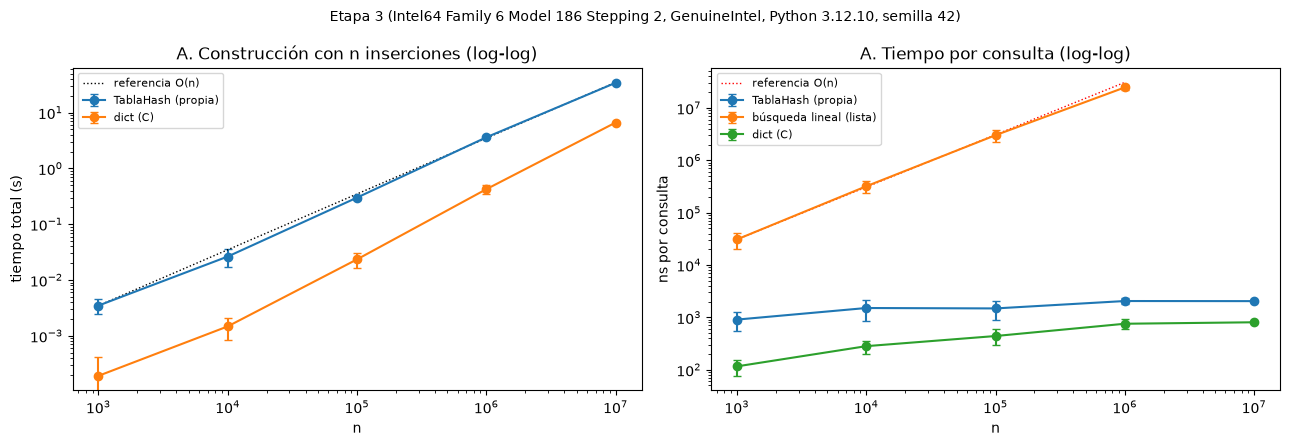

,operacion,metodo,n,promedio_s,desv_est_s,ns_por_operacion,desv_ns,repeticiones
0,construccion,TablaHash (propia),1000,0.003482,0.001028,3482.0,1028.0,100
1,construccion,TablaHash (propia),10000,0.026341,0.009165,2634.0,917.0,100
2,construccion,TablaHash (propia),100000,0.299659,0.023509,2997.0,235.0,20
3,construccion,TablaHash (propia),1000000,3.605958,0.104027,3606.0,104.0,5
4,construccion,TablaHash (propia),10000000,34.162487,NaN,3416.0,NaN,1
5,construccion,dict (C),1000,0.000192,0.000224,192.0,224.0,100
6,construccion,dict (C),10000,0.001476,0.000648,148.0,65.0,100
7,construccion,dict (C),100000,0.023448,0.006821,234.0,68.0,20
8,construccion,dict (C),1000000,0.424006,0.071523,424.0,72.0,5
9,construccion,dict (C),10000000,6.631741,NaN,663.0,NaN,1


,metodo,pendiente_empirica,esperado,rango_n
0,TablaHash (propia),1.01,≈1 (n),"1,000 a 10,000,000"
1,dict (C),1.15,≈1 (n),"1,000 a 10,000,000"


,metodo,pendiente_empirica,esperado,rango_n
0,TablaHash (propia),0.08,≈0 (1),"1,000 a 10,000,000"
1,búsqueda lineal (lista),0.97,≈1 (n),"1,000 a 1,000,000"
2,dict (C),0.21,≈0 (1),"1,000 a 10,000,000"


In [12]:
def construir_tabla(claves):
    t = TablaHash()
    for i, k in enumerate(claves):
        t.insertar(k, i)
    return t

def construir_dict(claves):
    d = {}
    for i, k in enumerate(claves):
        d[k] = i
    return d

def consultar_tabla(tabla, consultas):
    for k in consultas:
        tabla.obtener(k)

def consultar_dict(d, consultas):
    for k in consultas:
        d.get(k)

def buscar_lineal(lista, clave):
    for i, k in enumerate(lista):
        if k == clave:
            return i
    return -1

def consultar_lineal(lista, consultas):
    for k in consultas:
        buscar_lineal(lista, k)


ruta_a = CARPETA_RESULTADOS / "etapa3_lookup_tiempos.csv"
if ruta_a.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_a = pd.read_csv(ruta_a)
    print(f"Resultados leídos de {ruta_a.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS:
        claves = generar_asins(n)
        rng = random.Random(SEED + n)
        for rep in range(REPETICIONES[n]):
            for nombre, funcion in [("TablaHash (propia)", construir_tabla), ("dict (C)", construir_dict)]:
                filas.append({"operacion": "construccion", "metodo": nombre, "n": n, "repeticion": rep,
                              "operaciones": n, "segundos": medir(funcion, claves)})
        tabla, d = construir_tabla(claves), construir_dict(claves)
        for rep in range(REPETICIONES[n]):
            consultas = [claves[rng.randrange(n)] for _ in range(CONSULTAS_POR_REPETICION)]
            for nombre, funcion, estructura in [("TablaHash (propia)", consultar_tabla, tabla),
                                                ("dict (C)", consultar_dict, d)]:
                filas.append({"operacion": "consulta", "metodo": nombre, "n": n, "repeticion": rep,
                              "operaciones": len(consultas), "segundos": medir(funcion, estructura, consultas)})
            if n <= LIMITE_LINEAL:
                consultas_l = consultas[:CONSULTAS_LINEAL[n]]
                filas.append({"operacion": "consulta", "metodo": "búsqueda lineal (lista)", "n": n, "repeticion": rep,
                              "operaciones": len(consultas_l), "segundos": medir(consultar_lineal, claves, consultas_l)})
        del claves, tabla, d
        print(f"n = {n:>10,} medido")
    tiempos_a = pd.DataFrame(filas)
    tiempos_a.to_csv(ruta_a, index=False)
    print(f"Resultados guardados en {ruta_a.relative_to(RAIZ)}")

tiempos_a["ns_por_operacion"] = tiempos_a["segundos"] / tiempos_a["operaciones"] * 1e9
resumen_a = (tiempos_a.groupby(["operacion", "metodo", "n"])
             .agg(promedio_s=("segundos", "mean"), desv_est_s=("segundos", "std"),
                  ns_por_operacion=("ns_por_operacion", "mean"), desv_ns=("ns_por_operacion", "std"),
                  repeticiones=("segundos", "count"))
             .reset_index())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
construccion = resumen_a.query("operacion == 'construccion'")
consulta = resumen_a.query("operacion == 'consulta'")
for nombre, datos in construccion.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3, label=nombre)
n_ref = np.array(TAMANOS, dtype=float)
base = construccion.query("metodo == 'TablaHash (propia)'").iloc[0]
ax1.plot(n_ref, base["promedio_s"] * n_ref / base["n"], "k:", lw=1, label="referencia O(n)")
for nombre, datos in consulta.groupby("metodo"):
    ax2.errorbar(datos["n"], datos["ns_por_operacion"], yerr=datos["desv_ns"], marker="o", capsize=3, label=nombre)
base_l = consulta.query("metodo == 'búsqueda lineal (lista)'").iloc[0]
n_l = n_ref[n_ref <= LIMITE_LINEAL]
ax2.plot(n_l, base_l["ns_por_operacion"] * n_l / base_l["n"], "r:", lw=1, label="referencia O(n)")
for ax, titulo, ylabel in [(ax1, "A. Construcción con n inserciones (log-log)", "tiempo total (s)"),
                           (ax2, "A. Tiempo por consulta (log-log)", "ns por consulta")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel(ylabel); ax.set_title(titulo); ax.legend(fontsize=8)
plt.suptitle(f"Etapa 3 ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa3_lookup.png", dpi=150)
plt.show()

display(resumen_a.round({"promedio_s": 6, "desv_est_s": 6, "ns_por_operacion": 0, "desv_ns": 0}))
display(pendientes(construccion, "promedio_s", {"TablaHash (propia)": "≈1 (n)", "dict (C)": "≈1 (n)"}))
pendientes(consulta, "ns_por_operacion", {"TablaHash (propia)": "≈0 (1)", "dict (C)": "≈0 (1)",
                                          "búsqueda lineal (lista)": "≈1 (n)"})

### Experimento B. Caché LRU sobre el stream real

Se usa la secuencia real de consultas de la etapa 3, es decir, el `parent_asin` de cada evento con producto en el orden de servicio. Para cada capacidad se sirve la secuencia completa. Un acierto devuelve el registro desde la caché y un fallo lo lee del disco y lo guarda en la caché. Se comparan tres variantes.

- `CacheLRU` propia.
- LRU con `OrderedDict`, la implementación habitual en Python, escrita en C.
- Sin caché, con una lectura en disco por consulta.

La tasa de aciertos no depende de la implementación, solo de la capacidad. La cota superior es la tasa con capacidad infinita, 1 − (productos distintos / consultas), porque la primera consulta de cada producto siempre es un fallo. Cada configuración se repite 3 veces, porque cada pasada sirve unos 8.5 millones de consultas y la variante sin caché tarda varios minutos. Las capacidades llegan a 250 000 productos, más que los productos distintos del stream.

repetición 1 de 3 medida


repetición 2 de 3 medida


repetición 3 de 3 medida
Resultados guardados en results\etapa3_lru.csv


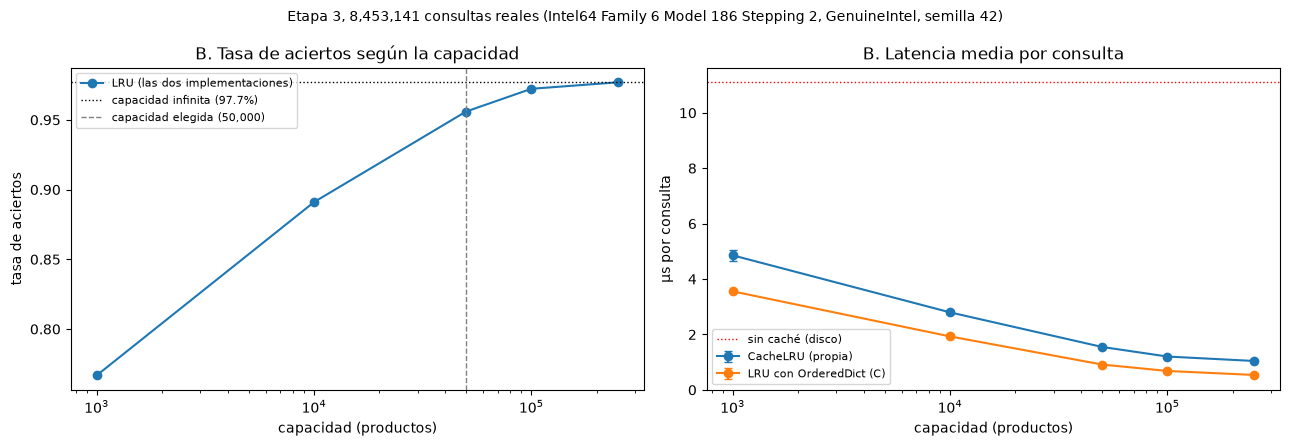

Consultas: 8,453,141   productos distintos: 195,019   cota superior de la tasa de aciertos: 97.7%


,metodo,capacidad,tasa_aciertos,us_por_consulta,desv_us,repeticiones
0,CacheLRU (propia),1000,0.7668,4.86,0.21,3
1,CacheLRU (propia),10000,0.8911,2.80,0.06,3
2,CacheLRU (propia),50000,0.9560,1.55,0.03,3
3,CacheLRU (propia),100000,0.9723,1.20,0.01,3
4,CacheLRU (propia),250000,0.9769,1.04,0.02,3
5,LRU con OrderedDict (C),1000,0.7668,3.56,0.04,3
6,LRU con OrderedDict (C),10000,0.8911,1.93,0.07,3
7,LRU con OrderedDict (C),50000,0.9560,0.91,0.03,3
8,LRU con OrderedDict (C),100000,0.9723,0.68,0.06,3
9,LRU con OrderedDict (C),250000,0.9769,0.54,0.02,3


In [13]:
CAPACIDADES = [1_000, 10_000, 50_000, 100_000, 250_000]
REPETICIONES_B = 3
cota_superior = 1 - len(set(secuencia)) / len(secuencia)


class LRUOrderedDict:
    """Línea base: LRU sobre OrderedDict (move_to_end y popitem en O(1))."""

    def __init__(self, capacidad):
        self.capacidad = capacidad
        self.datos = OrderedDict()

    def obtener(self, clave):
        valor = self.datos.get(clave)
        if valor is not None:
            self.datos.move_to_end(clave)
        return valor

    def poner(self, clave, valor):
        self.datos[clave] = valor
        self.datos.move_to_end(clave)
        if len(self.datos) > self.capacidad:
            self.datos.popitem(last=False)


def servir(cache, secuencia):
    aciertos = 0
    for asin in secuencia:
        registro = cache.obtener(asin)
        if registro is None:
            cache.poner(asin, almacen.leer(asin))
        else:
            aciertos += 1
    return aciertos


def servir_sin_cache(secuencia):
    for asin in secuencia:
        almacen.leer(asin)


ruta_b = CARPETA_RESULTADOS / "etapa3_lru.csv"
if ruta_b.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_b = pd.read_csv(ruta_b)
    print(f"Resultados leídos de {ruta_b.relative_to(RAIZ)}")
else:
    filas = []
    for rep in range(REPETICIONES_B):
        filas.append({"metodo": "sin caché (disco)", "capacidad": 0, "repeticion": rep, "tasa_aciertos": 0.0,
                      "segundos": medir(servir_sin_cache, secuencia)})
        for capacidad in CAPACIDADES:
            for nombre, clase in [("CacheLRU (propia)", CacheLRU), ("LRU con OrderedDict (C)", LRUOrderedDict)]:
                cache_b = clase(capacidad)
                resultado = {}
                segundos = medir(lambda: resultado.update(aciertos=servir(cache_b, secuencia)))
                filas.append({"metodo": nombre, "capacidad": capacidad, "repeticion": rep,
                              "tasa_aciertos": resultado["aciertos"] / len(secuencia), "segundos": segundos})
        print(f"repetición {rep + 1} de {REPETICIONES_B} medida")
    tiempos_b = pd.DataFrame(filas)
    tiempos_b.to_csv(ruta_b, index=False)
    print(f"Resultados guardados en {ruta_b.relative_to(RAIZ)}")

tiempos_b["us_por_consulta"] = tiempos_b["segundos"] / len(secuencia) * 1e6
resumen_b = (tiempos_b.groupby(["metodo", "capacidad"])
             .agg(tasa_aciertos=("tasa_aciertos", "mean"), us_por_consulta=("us_por_consulta", "mean"),
                  desv_us=("us_por_consulta", "std"), repeticiones=("segundos", "count"))
             .reset_index())
sin_cache_us = resumen_b.query("capacidad == 0")["us_por_consulta"].iloc[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
propia = resumen_b.query("metodo == 'CacheLRU (propia)'")
ax1.plot(propia["capacidad"], propia["tasa_aciertos"], marker="o", label="LRU (las dos implementaciones)")
ax1.axhline(cota_superior, color="k", ls=":", lw=1, label=f"capacidad infinita ({cota_superior:.1%})")
ax1.axvline(CAPACIDAD_CACHE, color="gray", ls="--", lw=1, label=f"capacidad elegida ({CAPACIDAD_CACHE:,})")
ax1.set_xscale("log"); ax1.set_xlabel("capacidad (productos)"); ax1.set_ylabel("tasa de aciertos")
ax1.set_title("B. Tasa de aciertos según la capacidad"); ax1.legend(fontsize=8)
for nombre, datos in resumen_b.query("capacidad > 0").groupby("metodo"):
    ax2.errorbar(datos["capacidad"], datos["us_por_consulta"], yerr=datos["desv_us"], marker="o", capsize=3, label=nombre)
ax2.axhline(sin_cache_us, color="r", ls=":", lw=1, label="sin caché (disco)")
ax2.set_xscale("log"); ax2.set_xlabel("capacidad (productos)"); ax2.set_ylabel("µs por consulta")
ax2.set_title("B. Latencia media por consulta"); ax2.legend(fontsize=8)
plt.suptitle(f"Etapa 3, {len(secuencia):,} consultas reales ({PLATAFORMA['procesador']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa3_lru.png", dpi=150)
plt.show()

print(f"Consultas: {len(secuencia):,}   productos distintos: {len(set(secuencia)):,}   "
      f"cota superior de la tasa de aciertos: {cota_superior:.1%}")
resumen_b.round({"tasa_aciertos": 4, "us_por_consulta": 2, "desv_us": 2})

### Experimento C. Matriz dispersa

El stream real tiene unos 8.4 millones de interacciones. Para medir de 1K a 10M con la misma estructura se generan interacciones sintéticas que reproducen cuatro proporciones medidas en el stream real. El tamaño de 10M queda cerca del stream real y permite comparar las dos matrices.

- **Usuarios.** Uno por cada 7.7 interacciones, elegidos con probabilidad uniforme.
- **Celdas.** Cada par (usuario, producto) recibe en promedio 3.89 interacciones, porque un recorrido de compra suma vista, carrito, compra y reseña sobre el mismo producto.
- **Productos.** Se eligen entre los 710 503 productos del catálogo con una distribución de Zipf de exponente 1.1. Con ese exponente, 2.17 millones de celdas cubren unos 212 000 productos distintos, cerca de los 195 019 del stream real.
- **Tipos de evento.** Con la frecuencia real de vistas, carritos, compras, reseñas y devoluciones, y su peso de la tabla del paso 5.

Para n = 1K, 10K, 100K, 1M y 10M se mide el tiempo de construcción de la DOK propia y de una DOK con `dict`, el tiempo de conversión a CSR y la memoria de cada representación. Las repeticiones son 100, 20, 5, 3 y 1 para cada tamaño, porque construir la DOK propia con 10M interacciones tarda cerca de un minuto. La memoria actual y pico de las DOK se mide con `tracemalloc` hasta 1M, porque con 10M `tracemalloc` hace la construcción varias veces más lenta. La memoria de la CSR se calcula con el tamaño de sus arreglos, y la de la matriz densa como filas × columnas × 8 bytes, porque construirla no es viable. La construcción debe ser O(n), con pendiente log-log cercana a 1. La memoria de la CSR debe crecer con el número de celdas no nulas y la de la matriz densa con el producto de filas por columnas.

Stream real: 8,438,123 interacciones, 0.1300 usuarios por interacción, 3.89 interacciones por celda


n =      1,000 medido


n =     10,000 medido


n =    100,000 medido


n =  1,000,000 medido


n = 10,000,000 medido
Resultados guardados en results\etapa3_matriz.csv


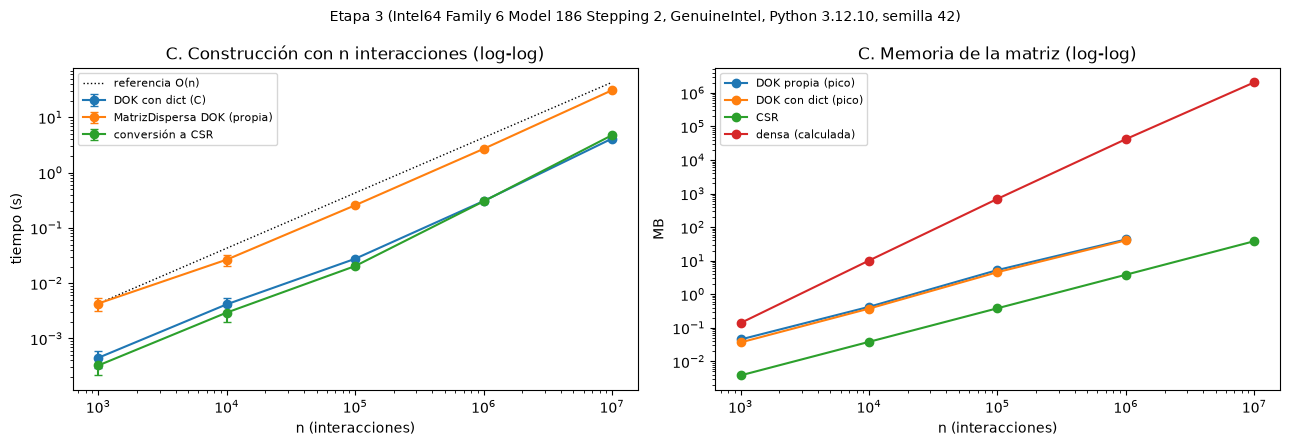

,metodo,n,promedio_s,desv_est_s,repeticiones
0,DOK con dict (C),1000,0.000447,0.000155,100
1,DOK con dict (C),10000,0.004149,0.001285,20
2,DOK con dict (C),100000,0.027638,0.000876,5
3,DOK con dict (C),1000000,0.305674,0.009053,3
4,DOK con dict (C),10000000,4.123020,NaN,1
5,MatrizDispersa DOK (propia),1000,0.004290,0.001181,100
6,MatrizDispersa DOK (propia),10000,0.026667,0.006310,20
7,MatrizDispersa DOK (propia),100000,0.256789,0.006452,5
8,MatrizDispersa DOK (propia),1000000,2.688790,0.102743,3
9,MatrizDispersa DOK (propia),10000000,30.856652,NaN,1


,n,filas_matriz,columnas_matriz,nnz,mb_dok_propia_actual,mb_dok_propia_pico,mb_dok_dict_actual,mb_dok_dict_pico,mb_csr,mb_densa,densidad
0,1000,105,165,247,0.045,0.045,0.030,0.037,0.004,0.1,0.014257
1,10000,1109,1138,2435,0.421,0.421,0.321,0.373,0.038,10.1,0.001929
2,100000,11093,7845,24425,3.749,5.253,3.801,4.546,0.382,696.2,0.000281
3,1000000,111016,47219,243620,34.305,42.833,34.611,40.378,3.812,41936.5,0.000046
4,10000000,1113156,232212,2437355,NaN,NaN,NaN,NaN,38.154,2067905.4,0.000009


,metodo,pendiente_empirica,esperado,rango_n
0,DOK con dict (C),0.98,≈1 (n),"1,000 a 10,000,000"
1,MatrizDispersa DOK (propia),0.97,≈1 (n),"1,000 a 10,000,000"
2,conversión a CSR,1.03,≈1-1.1 (nnz log nnz),"1,000 a 10,000,000"


In [14]:
REPETICIONES_C = {1_000: 100, 10_000: 20, 100_000: 5, 1_000_000: 3, 10_000_000: 1}
LIMITE_MEMORIA_C = 1_000_000
interacciones_reales = sum(tipos[t] for t in PESOS)
USUARIOS_POR_INTERACCION = etapa.matriz.forma[0] / interacciones_reales
INTERACCIONES_POR_CELDA = interacciones_reales / len(etapa.matriz.celdas)
FRECUENCIA_TIPO = Counter({t: tipos[t] for t in PESOS})
N_PRODUCTOS = len(almacen)
EXPONENTE_ZIPF = 1.1
print(f"Stream real: {interacciones_reales:,} interacciones, {USUARIOS_POR_INTERACCION:.4f} usuarios por interacción, "
      f"{INTERACCIONES_POR_CELDA:.2f} interacciones por celda")


def interacciones_sinteticas(n, semilla=SEED):
    # Tres listas paralelas (usuario, producto, peso) con las proporciones del stream real
    rng = np.random.default_rng(semilla)
    n_celdas = max(1, round(n / INTERACCIONES_POR_CELDA))
    n_usuarios = max(1, round(n * USUARIOS_POR_INTERACCION))
    zipf = np.arange(1, N_PRODUCTOS + 1, dtype=np.float64) ** -EXPONENTE_ZIPF
    usuario_celda = rng.integers(0, n_usuarios, size=n_celdas)
    producto_celda = rng.choice(N_PRODUCTOS, size=n_celdas, p=zipf / zipf.sum())
    celda = np.sort(rng.integers(0, n_celdas, size=n))
    tipos = list(FRECUENCIA_TIPO)
    frecuencia = np.array([FRECUENCIA_TIPO[t] for t in tipos], dtype=np.float64)
    tipo = rng.choice(len(tipos), size=n, p=frecuencia / frecuencia.sum())
    usuarios = [f"U{i:09d}" for i in range(n_usuarios)]
    productos = [f"B{i:09d}" for i in range(N_PRODUCTOS)]
    pesos = [PESOS[t] for t in tipos]
    return ([usuarios[i] for i in usuario_celda[celda].tolist()],
            [productos[i] for i in producto_celda[celda].tolist()],
            [pesos[i] for i in tipo.tolist()])


def construir_dok_propia(datos):
    matriz = MatrizDispersa()
    for u, p, w in zip(*datos):
        matriz.sumar(u, p, w)
    return matriz


def construir_dok_dict(datos):
    filas, columnas, celdas = {}, {}, {}
    for u, p, w in zip(*datos):
        i = filas.setdefault(u, len(filas))
        j = columnas.setdefault(p, len(columnas))
        celdas[(i, j)] = celdas.get((i, j), 0.0) + w
    return celdas


def medir_memoria(funcion, *args):
    # Devuelve (resultado, memoria actual, memoria pico) en bytes
    gc.collect()
    tracemalloc.start()
    resultado = funcion(*args)
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return resultado, actual, pico


ruta_c = CARPETA_RESULTADOS / "etapa3_matriz.csv"
if ruta_c.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_c = pd.read_csv(ruta_c)
    print(f"Resultados leídos de {ruta_c.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS:
        datos = interacciones_sinteticas(n)
        for rep in range(REPETICIONES_C[n]):
            filas.append({"metodo": "MatrizDispersa DOK (propia)", "n": n, "repeticion": rep,
                          "segundos": medir(construir_dok_propia, datos)})
            filas.append({"metodo": "DOK con dict (C)", "n": n, "repeticion": rep,
                          "segundos": medir(construir_dok_dict, datos)})
        if n <= LIMITE_MEMORIA_C:
            matriz_n, actual_propia, pico_propia = medir_memoria(construir_dok_propia, datos)
            dok_dict, actual_dict, pico_dict = medir_memoria(construir_dok_dict, datos)
            del dok_dict
        else:
            matriz_n = construir_dok_propia(datos)
            actual_propia = pico_propia = actual_dict = pico_dict = np.nan
        for rep in range(REPETICIONES_C[n]):
            filas.append({"metodo": "conversión a CSR", "n": n, "repeticion": rep, "segundos": medir(matriz_n.a_csr)})
        csr_n = matriz_n.a_csr()
        n_filas, n_columnas = matriz_n.forma
        for fila in filas:
            if fila["n"] == n:
                fila.update(filas_matriz=n_filas, columnas_matriz=n_columnas, nnz=csr_n.nnz,
                            mb_dok_propia_actual=actual_propia / 1e6, mb_dok_propia_pico=pico_propia / 1e6,
                            mb_dok_dict_actual=actual_dict / 1e6, mb_dok_dict_pico=pico_dict / 1e6,
                            mb_csr=csr_n.bytes() / 1e6, mb_densa=n_filas * n_columnas * 8 / 1e6)
        del datos, matriz_n, csr_n
        print(f"n = {n:>10,} medido")
    tiempos_c = pd.DataFrame(filas)
    tiempos_c.to_csv(ruta_c, index=False)
    print(f"Resultados guardados en {ruta_c.relative_to(RAIZ)}")

resumen_c = resumir(tiempos_c)
memoria_c = tiempos_c.drop_duplicates("n")[["n", "filas_matriz", "columnas_matriz", "nnz", "mb_dok_propia_actual",
                                            "mb_dok_propia_pico", "mb_dok_dict_actual", "mb_dok_dict_pico",
                                            "mb_csr", "mb_densa"]].reset_index(drop=True)
memoria_c["densidad"] = memoria_c["nnz"] / (memoria_c["filas_matriz"] * memoria_c["columnas_matriz"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, datos in resumen_c.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3, label=nombre)
base = resumen_c.query("metodo == 'MatrizDispersa DOK (propia)'").iloc[0]
n_ref = np.array(TAMANOS, dtype=float)
ax1.plot(n_ref, base["promedio_s"] * n_ref / base["n"], "k:", lw=1, label="referencia O(n)")
for columna, nombre in [("mb_dok_propia_pico", "DOK propia (pico)"), ("mb_dok_dict_pico", "DOK con dict (pico)"),
                        ("mb_csr", "CSR"), ("mb_densa", "densa (calculada)")]:
    ax2.plot(memoria_c["n"], memoria_c[columna], marker="o", label=nombre)
for ax, titulo, ylabel in [(ax1, "C. Construcción con n interacciones (log-log)", "tiempo (s)"),
                           (ax2, "C. Memoria de la matriz (log-log)", "MB")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n (interacciones)"); ax.set_ylabel(ylabel); ax.set_title(titulo); ax.legend(fontsize=8)
plt.suptitle(f"Etapa 3 ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa3_matriz.png", dpi=150)
plt.show()

display(resumen_c.round(6))
display(memoria_c.round({"mb_dok_propia_actual": 3, "mb_dok_propia_pico": 3, "mb_dok_dict_actual": 3,
                         "mb_dok_dict_pico": 3, "mb_csr": 3, "mb_densa": 1, "densidad": 8}))
pendientes(resumen_c, "promedio_s", {"MatrizDispersa DOK (propia)": "≈1 (n)", "DOK con dict (C)": "≈1 (n)",
                                     "conversión a CSR": "≈1-1.1 (nnz log nnz)"})

### Memoria de la tabla hash

Se mide con `tracemalloc` la memoria actual (lo que queda ocupado al terminar) y la memoria pico (el máximo durante la construcción) al construir la tabla con n claves. No se cuentan las claves, que ya existen antes de la medición. El pico incluye la reconstrucción, durante la cual conviven la tabla vieja y la nueva. Se mide hasta 1M, porque `tracemalloc` registra cada asignación y hace muy lenta la construcción con 10M.

In [15]:
ruta_memoria = CARPETA_RESULTADOS / "etapa3_memoria.csv"
if ruta_memoria.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria = pd.read_csv(ruta_memoria)
else:
    filas = []
    for n in [1_000, 10_000, 100_000, 1_000_000]:
        claves = generar_asins(n)
        for nombre, funcion in [("TablaHash (propia)", construir_tabla), ("dict (C)", construir_dict)]:
            estructura, actual, pico = medir_memoria(funcion, claves)
            filas.append({"metodo": nombre, "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
            del estructura
    memoria = pd.DataFrame(filas)
    memoria.to_csv(ruta_memoria, index=False)

memoria["bytes_por_clave_actual"] = memoria["actual_mb"] * 1e6 / memoria["n"]
memoria["bytes_por_clave_pico"] = memoria["pico_mb"] * 1e6 / memoria["n"]
memoria.pivot(index="n", columns="metodo", values=["bytes_por_clave_actual", "bytes_por_clave_pico"]).round(1)

bytes_por_clave_actual          bytes_por_clave_pico         
metodo      TablaHash (propia) dict (C)   TablaHash (propia) dict (C)
n                                                                    
1000                      94.7     47.0                101.3     51.2
10000                     64.8     48.1                 85.1     48.1
100000                    71.0     66.4                137.5     82.1
1000000                   61.7     58.8                109.5     65.7

### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/`. Al medir de nuevo pueden variar ligeramente.

- **Índice del catálogo.** Con 710 503 productos la tabla tiene 1 048 576 posiciones y un factor de carga de 0.678. El sondeo medio medido es 2.048 posiciones, frente a 2.051 de la fórmula de Knuth. CRC32 reparte las claves de forma suficientemente uniforme para que se cumpla el análisis teórico.
- **Experimento A, construcción.** `TablaHash` tiene una pendiente de 1.01, coherente con O(n). Cada inserción cuesta entre 2.6 y 3.6 µs en todo el rango, de 1K a 10M. `dict` es entre 8 y 18 veces más rápido porque está escrito en C. Su pendiente (1.15) es mayor porque con n grande el acceso a memoria pasa a dominar su costo.
- **Experimento A, consulta.** El tiempo por consulta de `TablaHash` pasa de 0.9 µs a 1K a 2.0 µs a 10M, con pendiente 0.08. El de `dict` pasa de 0.12 a 0.81 µs, con pendiente 0.21. Las dos son O(1). El aumento moderado se debe a que una tabla grande no cabe en la caché del procesador. La búsqueda lineal tiene pendiente 0.97, coherente con O(n). A 1M tarda 24.7 ms por consulta, unas 12 000 veces más que `TablaHash`.
- **Experimento B.** Con 8 453 141 consultas sobre 195 019 productos distintos, la tasa de aciertos sube de 76.7 % con 1 000 productos a 89.1 % con 10 000, 95.6 % con 50 000 y 97.2 % con 100 000. Con 250 000 llega a la cota de 97.7 %, porque todos los productos distintos caben en la caché. La capacidad elegida, 50 000, alcanza el 98 % de la cota con el 26 % de los productos distintos. La latencia media baja de 11.1 µs sin caché a 1.55 µs, 7 veces menos. La LRU con `OrderedDict` es 1.7 veces más rápida que la propia con la misma tasa de aciertos, por estar escrita en C.
- **Experimento C.** La construcción de la DOK tiene pendientes de 0.97 (propia) y 0.98 (`dict`), coherentes con O(n). La DOK propia cuesta unos 3 µs por interacción y tarda 31 s con 10M, 7.5 veces más que la DOK con `dict` (4.1 s). La conversión a CSR tiene pendiente 1.03. Con 10M interacciones sintéticas la matriz tiene 1 113 156 usuarios × 232 212 productos y 2 437 355 celdas no nulas, cerca de la matriz real del paso 6 (1 096 990 × 195 019 con 2 169 391 celdas), que viene de 8.4 millones de interacciones. La CSR sintética ocupa 38 MB y la real 35 MB, frente a unos 2 TB de una matriz densa. Con 1M interacciones la DOK propia ocupa 34.3 MB (42.8 MB de pico), igual que la DOK con `dict` (34.6 MB, 40.4 MB de pico), y la CSR ocupa 3.8 MB, nueve veces menos.
- **Memoria de la tabla hash.** Al terminar la construcción, `TablaHash` ocupa entre 62 y 95 bytes por clave y `dict` entre 47 y 66. Con 1M claves la diferencia es pequeña (62 frente a 59). El pico es mayor, entre 85 y 138 bytes por clave para `TablaHash` y entre 48 y 82 para `dict`, porque durante cada reconstrucción conviven los arreglos viejos y los nuevos. La tabla propia ocupa más porque guarda claves y valores en dos listas separadas y mantiene al menos un 30 % de posiciones libres, mientras que `dict` guarda las entradas en un arreglo compacto con un índice aparte.
- **Etapa completa.** Procesa 9 940 617 eventos en 104 s, unos 10 µs por evento con la lectura del archivo incluida. Su pico de memoria es de 516 MB sin contar el índice del catálogo. La matriz real ocupa la mayor parte, con 1.1 millones de usuarios.
- **Stock sintético.** De 1 978 936 compras, 73 678 (3.7 %) llegaron sin stock, en 11 785 productos, y hubo 50 906 reposiciones. Los productos más comprados agotan sus 5 a 50 unidades antes de reponerse a las 48 horas. Los parámetros del stock no salen del dataset y deben ajustarse si la etapa 9 muestra la disponibilidad.

Las estructuras propias cumplen las complejidades teóricas. Se mantienen en la etapa porque la tabla hash, la caché LRU y la matriz dispersa son las estructuras evaluadas del bloque S4. `dict` y `OrderedDict` quedan como referencia de lo que se ganaría con una implementación en C.

## Paso 8. Salida de la etapa 3

La etapa produce cuatro salidas en `data/interim/<CATEGORIA>/`.

| Archivo | Contenido | Etapas que lo usan |
| --- | --- | --- |
| `etapa3_catalogo.jsonl` | Catálogo en disco, un registro por producto con el precio ya convertido | 4 (B+Tree sobre el archivo), 5 (atributos del vector), 9 (fichas de producto) |
| `etapa3_estado_productos.parquet` | Contadores, stock, disponibilidad y precio observado de cada producto con actividad | 5 (popularidad como atributo), 9 (ranking por popularidad y disponibilidad) |
| `etapa3_matriz_usuario_producto.npz` | Matriz CSR usuario × producto con los identificadores de filas y columnas | 7 (similitud entre productos por sus usuarios), 9 (recomendaciones) |
| `etapa3_metricas.json` | Métricas de la ejecución | Informe y panel de la etapa 9 |

Las etapas siguientes también pueden importar `EtapaAlmacenamiento` desde `src/stage3_storage.py` para consultar productos en línea.

In [16]:
ruta_estados = CARPETA_INTERIM / "etapa3_estado_productos.parquet"
pq.write_table(pa.Table.from_pandas(estados, preserve_index=False), ruta_estados, compression="zstd")

csr = etapa.matriz.a_csr()
ruta_matriz = CARPETA_INTERIM / "etapa3_matriz_usuario_producto.npz"
guardar_matriz(ruta_matriz, csr, etapa.matriz.usuarios, etapa.matriz.productos)

metricas = {
    "eventos": m["eventos"], "sin_producto": m["sin_producto"], "fuera_de_catalogo": m["fuera_de_catalogo"],
    "segundos": round(t_etapa, 3), "memoria_pico_mb": round(pico_etapa / 1e6, 1),
    "cache": {"capacidad": cache.capacidad, "aciertos": cache.aciertos, "fallos": cache.fallos,
              "desalojos": cache.desalojos, "tasa_aciertos": round(cache.tasa_aciertos(), 4)},
    "productos_con_estado": len(etapa.estados), "reposiciones": m["reposiciones"],
    "matriz": {"usuarios": csr.n_filas, "productos": csr.n_columnas, "nnz": csr.nnz, "bytes_csr": csr.bytes()},
    "plataforma": PLATAFORMA,
}
ruta_metricas = CARPETA_INTERIM / "etapa3_metricas.json"
ruta_metricas.write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")

# Comprobación: la matriz guardada se lee igual
csr_leida, usuarios_leidos, productos_leidos = cargar_matriz(ruta_matriz)
assert csr_leida.nnz == csr.nnz and usuarios_leidos == etapa.matriz.usuarios and productos_leidos == etapa.matriz.productos

for ruta in (RUTA_CATALOGO, ruta_estados, ruta_matriz, ruta_metricas):
    print(f"{ruta.relative_to(RAIZ)}: {ruta.stat().st_size / 1e6:,.1f} MB")

data\interim\Office_Products\etapa3_catalogo.jsonl: 303.1 MB
data\interim\Office_Products\etapa3_estado_productos.parquet: 4.2 MB
data\interim\Office_Products\etapa3_matriz_usuario_producto.npz: 38.0 MB
data\interim\Office_Products\etapa3_metricas.json: 0.0 MB


### Datos para las etapas 7 y 9

Se muestran dos ejemplos de cómo las etapas siguientes pueden usar la salida.

- **Etapa 7.** La transpuesta de la matriz da, para cada producto, el conjunto de usuarios que interactuaron con él. Ese conjunto es la entrada natural de MinHash para estimar la similitud de Jaccard entre productos.
- **Etapa 9.** La fila de un usuario en la CSR da los productos con los que interactuó y su peso, que es la base de sus recomendaciones.

In [17]:
transpuesta = csr.transpuesta()
usuarios_por_producto = np.diff(np.frombuffer(transpuesta.indptr, dtype=np.int64))
productos_por_usuario = np.diff(np.frombuffer(csr.indptr, dtype=np.int64))
print(f"Usuarios por producto: media {usuarios_por_producto.mean():.2f}, máximo {usuarios_por_producto.max()}")
print(f"Productos por usuario: media {productos_por_usuario.mean():.2f}, máximo {productos_por_usuario.max()}")

i = int(productos_por_usuario.argmax())
columnas, pesos = csr.fila(i)
pd.DataFrame({"parent_asin": [etapa.matriz.productos[j] for j in columnas], "peso": list(pesos),
              "titulo": [etapa.ficha(etapa.matriz.productos[j])["title"][:70] for j in columnas]}
             ).sort_values("peso", ascending=False).head(10)

Usuarios por producto: media 11.12, máximo 2929
Productos por usuario: media 1.98, máximo 1557


,parent_asin,peso,titulo
12,B0B3MX7LVG,20.0,"EZlifego Double Sided Tape Heavy Duty, Extra L..."
30,B09PWTVGPW,12.0,"Alientape Nano Double Sided Tape, Multipurpose..."
272,B09YK1YBZ6,12.0,Jeff Kinney Diary of a Wimpy Kid 1-16 Books Bo...
169,B09NR9SYPF,12.0,The Original Everlasting Comfort Foot Rest for...
411,B0BG4Z8YY1,12.0,"Bonsaii 14-Sheet Microcut Paper Shredder, 60-M..."
8,B0BN478RWJ,12.0,HP DeskJet 2755e Wireless Color All-in-One Pri...
82,B07SQRQMKX,12.0,Canon CL-244 color cartridge Compatible to iP2...
124,B07YQXNFBB,12.0,Homall Office Chair High Back Computer Desk Ch...
814,B09V2S9QJV,8.0,CAGIE Leather Vintage Journal for Men Soft Cov...
1188,B0BLJN5HNQ,8.0,Lanxivi 5 PCS Gel Pens Quick Dry Ink Pens Blac...


## Resumen de la etapa 3

| Aspecto | Decisión |
| --- | --- |
| Tabla hash | Direccionamiento abierto con sondeo lineal, CRC32, lápidas y reconstrucción con factor de carga 0.7. O(1) esperado |
| Catálogo | Archivo de registros en disco con índice hash `parent_asin` → `(offset, largo)` |
| Caché | LRU propia (tabla hash + lista doblemente enlazada), capacidad 50 000 productos, O(1) por operación |
| Estado del producto | Contadores, stock sintético con reposición a las 48 h y precio observado, solo para productos con actividad |
| Matriz | Usuario × producto con pesos por tipo de evento. DOK durante el stream y CSR al cerrar |
| Salida | Catálogo en disco, estado de productos, matriz CSR y métricas en `data/interim/<CATEGORIA>/` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 11. Knuth, D. E. (1998). *The Art of Computer Programming, Vol. 3: Sorting and Searching* (2.ª ed.), sec. 6.4. Saad, Y. (2003). *Iterative Methods for Sparse Linear Systems* (2.ª ed.), sec. 3.4. Mattson, R. L., Gecsei, J., Slutz, D. R., y Traiger, I. L. (1970). Evaluation techniques for storage hierarchies. *IBM Systems Journal*, 9(2), 78-117.